# 04 · Granularity and Schemes

The fixes, built. Every knob in quantization exists to answer the outlier problem from
notebook 03:

- **Granularity** — per-tensor vs per-channel. The single most important lever.
- **Clipping** — tame the extremes before quantizing.
- **Scheme** — symmetric *absmax* vs asymmetric *zero-point*.
- **Target** — weights vs activations. Activations are harder, because their outliers
  live in *channels* that every token shares.

In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
if not (_root / "src").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import json
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

from src.artifacts import save_figure, save_json
from src.config import load_settings

settings = load_settings()
np.random.seed(settings.seed)
print("settings:", settings.model_dump())

settings: {'seed': 0, 'bit_widths': [8, 4], 'granularity': 'per_channel', 'channel_axis': 1, 'scheme': 'absmax', 'clip_percentile': 99.9, 'clip_sigma': 6.0, 'outlier_sigma': 6.0, 'model_name': 'distilgpt2', 'synthetic': {'rows': 256, 'cols': 256, 'outlier_scale': 10.0, 'n_outliers': 1}}


## The arena: every combination at once

We quantize a planted-outlier matrix under all combinations of bit-width, scheme, and
granularity, and read off the error. Per-channel (the lower pair of lines) is dramatically
better; zero-point edges out absmax; the gap widens at int4.

 bits    scheme granularity  rel_fro    snr_db  size_ratio
    8    absmax  per_tensor 0.201779 13.902498       0.250
    8    absmax per_channel 0.014083 37.025902       0.250
    8 zeropoint  per_tensor 0.105300 19.551394       0.250
    8 zeropoint per_channel 0.009208 40.716256       0.250
    4    absmax  per_tensor 0.937895  0.556913       0.125
    4    absmax per_channel 0.135444 17.364827       0.125
    4 zeropoint  per_tensor 0.936138  0.573203       0.125
    4 zeropoint per_channel 0.121811 18.286263       0.125


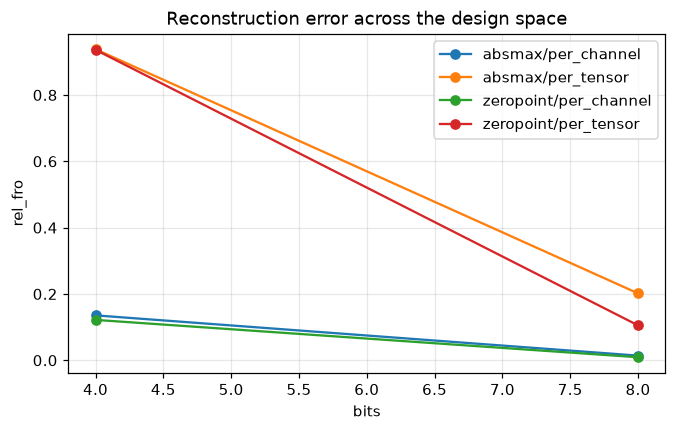

In [2]:
from src.evaluation.comparison import arena
from src.models.weights import planted_outlier_matrix
from src.visualisation import plot_error_vs_bits

w, mask = planted_outlier_matrix(rows=256, cols=256, outlier_scale=20.0, n_outliers=1, seed=0)
table = arena(w)
cols = ["bits", "scheme", "granularity", "rel_fro", "snr_db", "size_ratio"]
print(table[cols].to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
plot_error_vs_bits(table, metric="rel_fro", ax=ax)
ax.set_title("Reconstruction error across the design space")
save_figure(fig, "04_arena")
plt.show()

## Clipping has a sweet spot

Clipping the extreme values before quantizing shrinks the scale so the ordinary weights
get their resolution back. Clip too little and the outlier still dominates; clip too much
and you start damaging ordinary weights. The error traces a clear minimum.

no clipping: 21.514%   best (p=99.99): 0.975%


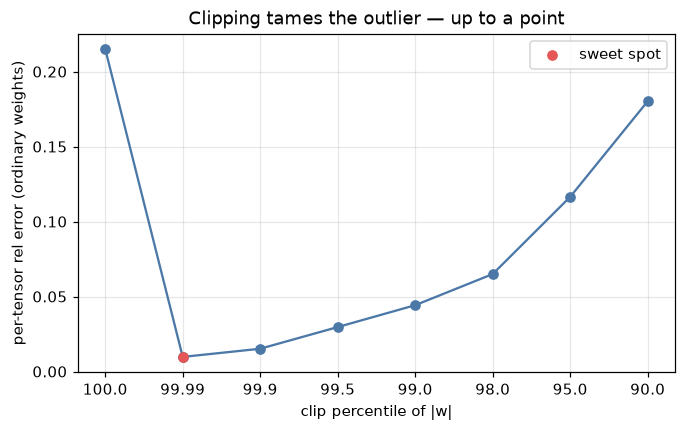

In [3]:
from src.evaluation.reconstruction import reconstruction_error
from src.quant.dequant import dequantize
from src.quant.granularity import quantize
from src.quant.outliers import clip_to_percentile

ordinary = w[~mask]
percentiles = [100.0, 99.99, 99.9, 99.5, 99.0, 98.0, 95.0, 90.0]
errs = []
for p in percentiles:
    wc = w if p >= 100.0 else clip_to_percentile(w, p)
    rec = dequantize(quantize(wc, bits=8, scheme="absmax", granularity="per_tensor"))[~mask]
    errs.append(reconstruction_error(ordinary, rec)["rel_fro"])

best_i = int(np.argmin(errs))
results = {"clip_percentiles": percentiles, "clip_errors": [float(e) for e in errs],
           "clip_best_percentile": percentiles[best_i], "clip_best_error": float(errs[best_i]),
           "clip_no_clip_error": float(errs[0])}
print(f"no clipping: {errs[0]:.3%}   best (p={percentiles[best_i]}): {errs[best_i]:.3%}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([str(p) for p in percentiles], errs, marker="o", color="#4C78A8")
ax.scatter([str(percentiles[best_i])], [errs[best_i]], color="#E45756", zorder=5, label="sweet spot")
ax.set_xlabel("clip percentile of |w|")
ax.set_ylabel("per-tensor rel error (ordinary weights)")
ax.set_title("Clipping tames the outlier — up to a point")
ax.legend()
save_figure(fig, "04_clipping")
plt.show()

## Why activations are harder

A weight outlier sits at one position, so a **per-row** scale confines it. An *activation*
outlier is a whole **channel** (column) that every token shares — so a per-row (per-token)
scale cannot contain it: every row carries the outlier channel. That is why weight-only
quantization is the common default, and activation quantization needs special handling.

weight matrix, per-row scale     : 1.668%  (outlier confined)
activation,   per-row scale      : 18.401%  (every row hit)
activation,   per-COLUMN scale   : 0.650%  (channel isolated)


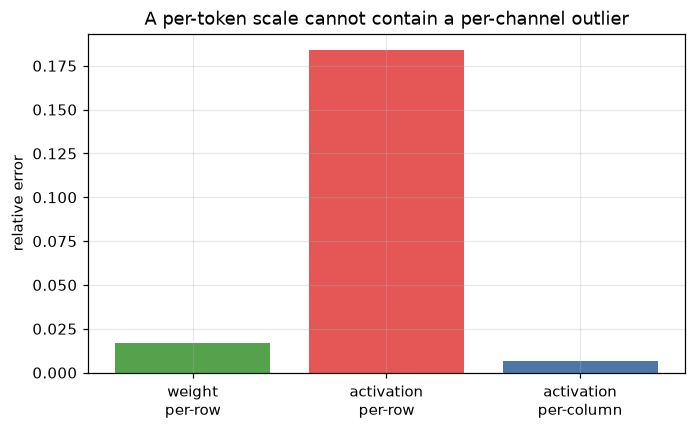

In [4]:
rng = np.random.default_rng(settings.seed)

# A weight-like matrix: one outlier in a single cell.
w_mat, w_mask = planted_outlier_matrix(128, 128, outlier_scale=20.0, n_outliers=1, seed=1)

# An activation-like matrix: one *channel* (column) is an outlier feature for every token.
act = rng.standard_normal((128, 128)).astype(np.float32)
ord_absmax = float(np.abs(act).max())
act[:, 7] = 20.0 * ord_absmax
act_ord = np.ones_like(act, dtype=bool)
act_ord[:, 7] = False  # the outlier channel

# Measure error on the ORDINARY entries only (excluding the outlier itself), as in nb 03.
def ordinary_err(m, axis, ord_mask):
    rec = dequantize(quantize(m, bits=8, granularity="per_channel", axis=axis))
    return reconstruction_error(m[ord_mask], rec[ord_mask])["rel_fro"]

results["weight_per_row_err"] = ordinary_err(w_mat, 1, ~w_mask)
results["activation_per_row_err"] = ordinary_err(act, 1, act_ord)
results["activation_per_col_err"] = ordinary_err(act, 0, act_ord)
print(f"weight matrix, per-row scale     : {results['weight_per_row_err']:.3%}  (outlier confined)")
print(f"activation,   per-row scale      : {results['activation_per_row_err']:.3%}  (every row hit)")
print(f"activation,   per-COLUMN scale   : {results['activation_per_col_err']:.3%}  (channel isolated)")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ["weight\nper-row", "activation\nper-row", "activation\nper-column"]
vals = [results["weight_per_row_err"], results["activation_per_row_err"], results["activation_per_col_err"]]
ax.bar(bars, vals, color=["#54A24B", "#E45756", "#4C78A8"])
ax.set_ylabel("relative error")
ax.set_title("A per-token scale cannot contain a per-channel outlier")
save_figure(fig, "04_activations")
plt.show()

## Takeaway

The knobs are not arbitrary: **per-channel** is how you contain weight outliers,
**clipping** trades a little bias for a much smaller scale, **zero-point** uses the grid
more efficiently off-centre, and **activations** are harder because their outliers are
shared across tokens. Every lever traces back to the scale-and-outlier insight.

In [5]:
path = save_json(results, "04_results")
print("saved", path)
{k: results[k] for k in list(results)[-5:]}

saved /workspaces/quantization_101/outputs/data/04_results.json


{'clip_best_error': 0.009745603427290916,
 'clip_no_clip_error': 0.21513977646827698,
 'weight_per_row_err': 0.016675464808940887,
 'activation_per_row_err': 0.1840144842863083,
 'activation_per_col_err': 0.006502417381852865}